# Reading the WRF Zarr stores in parallel with Dask

This notebook computes the seasonal cycle of **precipitable water (PW)** over 31 water years of the
1 km Idaho WRF simulation, reading about 1 TB of 3D water vapour from Zarr. It shows how to:

1. start a Dask cluster on a Borah compute node (or across several nodes),
2. open the Zarr stores lazily and see how they are chunked,
3. express the calculation once and let Dask run it in parallel,
4. measure how throughput scales with the number of workers,
5. avoid the access patterns these stores are slow at.

**Why workers matter here.** Each hour of a 3D variable is one Zarr chunk (~22 MB decoded, 348 × 327 × 49
float32). Reading is dominated by waiting on the network filesystem, not by arithmetic: a single-process
benchmark kept only 1.3 of 16 cores busy and read 0.23 GB/s. Many workers, each with several reads in
flight, hide that latency.

**Run it on a compute node, not the login node** (see the last cell for how to start Jupyter in a job).

## 1. Settings
Paths come from the repo's `config.yaml`, so the notebook finds the stores wherever they live.
Environment variables override the defaults (the repo's synthetic test uses that).

In [1]:
import os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import zarr
import matplotlib.pyplot as plt

REPO = Path(os.environ.get("WRF_ZARR_REPO", Path.cwd().parent)).resolve()
sys.path.insert(0, str(REPO))
import wrf_to_zarr as w
from tools.benchmark_pw import column_weights, p_top

CONFIG = os.environ.get("WRF_ZARR_CONFIG", str(REPO / "config.yaml"))
PTOP = float(os.environ["WRF_ZARR_PTOP"]) if "WRF_ZARR_PTOP" in os.environ else None  # Pa; None = read from grid_file
STRIDE = int(os.environ.get("WRF_ZARR_STRIDE", 6))                  # use every 6th hour: 00/06/12/18 UTC
SCALING_PERIOD = os.environ.get("WRF_ZARR_SCALING_PERIOD", "2010-07")  # one month for the scaling test
WORKER_COUNTS = [int(n) for n in os.environ.get("WRF_ZARR_WORKERS", "1,4,8,16").split(",")]

cfg = w.load_config(CONFIG)

## 2. Start a Dask cluster
`LocalCluster` uses the cores of the node this notebook runs on. Each **worker is a separate process**, so
decompression and NumPy run truly in parallel; `threads_per_worker=2` lets each one overlap reading with
computing.

Zarr itself issues reads asynchronously. `async.concurrency` caps how many reads each worker keeps in flight;
raising it from the default helps a lot on network filesystems like Borah's.

In [2]:
from dask.distributed import Client, LocalCluster

n_cores = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count()))
cluster = LocalCluster(n_workers=max(WORKER_COUNTS[0], 1), threads_per_worker=2,
                       memory_limit="auto", dashboard_address=":8787")
client = Client(cluster)

def zarr_settings():
    import zarr
    zarr.config.set({"async.concurrency": 32})
zarr_settings()
client.run(zarr_settings)

print(f"{n_cores} cores on this node; dashboard: {client.dashboard_link}")
client

16 cores on this node; dashboard: http://127.0.0.1:8787/status


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 1
Total threads: 2,Total memory: 8.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36311,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39046,Total threads: 2
Dashboard: http://127.0.0.1:40039/status,Memory: 8.00 GiB
Nanny: tcp://127.0.0.1:42006,


<details><summary><b>Using several nodes instead (dask-jobqueue)</b></summary>

`LocalCluster` is limited to one node. To spread workers over Slurm jobs, install `dask-jobqueue`
(`conda install -c conda-forge dask-jobqueue`, inside `dev-session`) and replace the cell above with:

```python
from dask_jobqueue import SLURMCluster
cluster = SLURMCluster(queue="bsudfq", cores=16, processes=8, memory="64GB",
                       walltime="02:00:00", job_script_prologue=["source ~/miniforge3/etc/profile.d/conda.sh",
                                                                  "conda activate wrf-zarr"])
cluster.scale(jobs=4)          # 4 Slurm jobs x 8 workers
client = Client(cluster)
```
Every worker reads the same files, so more nodes help only until the filesystem saturates; measure with
section 5 before asking for many.
</details>

## 3. Open the stores lazily
`open_zarr` reads only metadata. Nothing is loaded until we ask for numbers. Note the chunk layout:
`atmos_3d` is chunked **one hour per chunk** (whole 3D maps), `surface_met` **one day per chunk**.

In [3]:
a3 = xr.open_zarr(w.store_path(cfg, "atmos_3d"), consolidated=True)
sm = xr.open_zarr(w.store_path(cfg, "surface_met"), consolidated=True)
st = xr.open_zarr(w.store_path(cfg, "static"), consolidated=True)
print(a3["QVAPOR"])
print("\nchunks along time:", a3["QVAPOR"].chunks[0][:3], "...  (", len(a3["QVAPOR"].chunks[0]), "chunks )")

<xarray.DataArray 'QVAPOR' (time: 271752, level: 49, y: 327, x: 348)> Size: 6TB
dask.array<open_dataset-QVAPOR, shape=(271752, 49, 327, 348), dtype=float32, chunksize=(1, 49, 327, 348), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 2MB 1986-10-01 ... 2017-09-30T23:00:00
  * y        (y) float64 3kB -1.84e+05 -1.83e+05 -1.82e+05 ... 1.41e+05 1.42e+05
  * x        (x) float64 3kB -2.47e+05 -2.46e+05 -2.45e+05 ... 9.9e+04 1e+05
    lat      (y, x) float64 910kB dask.array<chunksize=(164, 174), meta=np.ndarray>
    lon      (y, x) float64 910kB dask.array<chunksize=(164, 174), meta=np.ndarray>
Dimensions without coordinates: level
Attributes:
    long_name:      Water vapor mixing ratio
    units:          kg kg-1
    wrf_name:       QVAPOR
    grid_mapping:   lambert_conformal
    standard_name:  humidity_mixing_ratio

chunks along time: (1, 1, 1) ...  ( 271752 chunks )


## 4. Write the calculation once, lazily
PW is the column integral of water vapour. The archive has no pressure fields after the first day, but WRF's
eta coordinate gives each layer's share of the dry-air column, $-\Delta\eta_k$, and surface pressure fixes the
column mass. With $A = \sum_k (-\Delta\eta_k)\, q_k$:

$$ PW = \frac{(p_s - p_{top})}{g}\,\frac{A}{1 + A} \quad [\mathrm{mm}] $$

`column_weights` and `p_top` come from `tools/benchmark_pw.py` (full-level eta from the grid file).
Everything below builds a task graph; no data is read yet.

In [4]:
G = 9.81
wts = column_weights(cfg, st, a3.sizes["level"])      # -DNW, sums to 1
ptop = p_top(cfg, PTOP)

def precipitable_water(q, psfc):
    a = (q * wts).sum("level")
    return (psfc - ptop) * a / (1 + a) / G

times = pd.DatetimeIndex(a3.time.values)
sel = np.flatnonzero(times.hour % STRIDE == 0)
good = ((a3["hour_present"] == 1) & (sm["hour_present"] == 1)).isel(time=sel)

pw = precipitable_water(a3["QVAPOR"].isel(time=sel), sm["PSFC"].isel(time=sel)).where(good)
pw.name, pw.attrs = "pw", {"units": "mm", "long_name": "precipitable water"}
print(f"{len(sel):,} hours selected; graph has {len(pw.data.__dask_graph__()):,} tasks")
pw

45,292 hours selected; graph has 2,404,260 tasks


<xarray.DataArray 'pw' (time: 45292, y: 327, x: 348)> Size: 41GB
dask.array<where, shape=(45292, 327, 348), dtype=float64, chunksize=(1, 327, 348), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 362kB 1986-10-01 ... 2017-09-30T18:00:00
  * y        (y) float64 3kB -1.84e+05 -1.83e+05 -1.82e+05 ... 1.41e+05 1.42e+05
  * x        (x) float64 3kB -2.47e+05 -2.46e+05 -2.45e+05 ... 9.9e+04 1e+05
    lat      (y, x) float64 910kB 42.6 42.6 42.61 42.61 ... 45.57 45.57 45.57
    lon      (y, x) float64 910kB -117.7 -117.7 -117.7 ... -113.4 -113.4 -113.4
Attributes:
    units:      mm
    long_name:  precipitable water

## 5. How does it scale with workers?
Compute one month of PW with different numbers of workers and record the read rate. On a shared
filesystem the curve flattens once the storage, not the node, is the limit; that knee is the worker count
to use.

In [5]:
period = pw.sel(time=SCALING_PERIOD) if SCALING_PERIOD in set(times[sel].strftime("%Y-%m")) else pw.isel(time=slice(0, 124))
gb = period.sizes["time"] * (a3["QVAPOR"].isel(time=0).nbytes + sm["PSFC"].isel(time=0).nbytes) / 1e9

rows = []
for n in WORKER_COUNTS:
    cluster.scale(n)
    client.wait_for_workers(n)
    client.run(zarr_settings)
    t0 = time.perf_counter()
    period.mean("time").compute()
    s = time.perf_counter() - t0
    rows.append({"workers": n, "seconds": round(s, 1), "GB_per_s": round(gb / s, 2)})
    print(rows[-1])

scaling = pd.DataFrame(rows).set_index("workers")
scaling["speedup"] = (scaling["seconds"].iloc[0] / scaling["seconds"]).round(1)
scaling

/bsuhome/aflores/miniforge3/envs/wrf-zarr/lib/python3.12/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 52.45 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


{'workers': 1, 'seconds': 57.6, 'GB_per_s': 0.05}


/bsuhome/aflores/miniforge3/envs/wrf-zarr/lib/python3.12/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 52.45 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


{'workers': 4, 'seconds': 25.9, 'GB_per_s': 0.11}


/bsuhome/aflores/miniforge3/envs/wrf-zarr/lib/python3.12/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 52.45 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


{'workers': 8, 'seconds': 18.4, 'GB_per_s': 0.15}


/bsuhome/aflores/miniforge3/envs/wrf-zarr/lib/python3.12/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 52.45 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


{'workers': 16, 'seconds': 21.8, 'GB_per_s': 0.13}


,seconds,GB_per_s,speedup
workers,,,
1,57.6,0.05,1.0
4,25.9,0.11,2.2
8,18.4,0.15,3.1
16,21.8,0.13,2.6


## 6. The full seasonal cycle
Use the best worker count from section 5 (by default the largest) and compute monthly means over the whole
record. `resample` keeps the work lazy; one `.compute()` runs all of it in parallel. Keep the dashboard open
to watch the workers.

In [6]:
best = int(scaling["GB_per_s"].idxmax())
cluster.scale(best); client.wait_for_workers(best); client.run(zarr_settings)

t0 = time.perf_counter()
monthly = pw.resample(time="MS").mean().compute()
s = time.perf_counter() - t0
gb_all = len(sel) * (a3["QVAPOR"].isel(time=0).nbytes + sm["PSFC"].isel(time=0).nbytes) / 1e9
print(f"{best} workers: {gb_all:,.0f} GB in {s/60:.1f} min ({gb_all/s:.2f} GB/s)")
monthly.to_netcdf("pw_monthly.nc")   # small (372 maps); reuse it without re-reading the store

/bsuhome/aflores/miniforge3/envs/wrf-zarr/lib/python3.12/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 61.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
2026-10-12 21:13:35,424 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,425 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,426 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,427 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,427 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,427 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,428 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-10-12 21:13:35,428 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


8 workers: 1,031 GB in 99.1 min (0.17 GB/s)


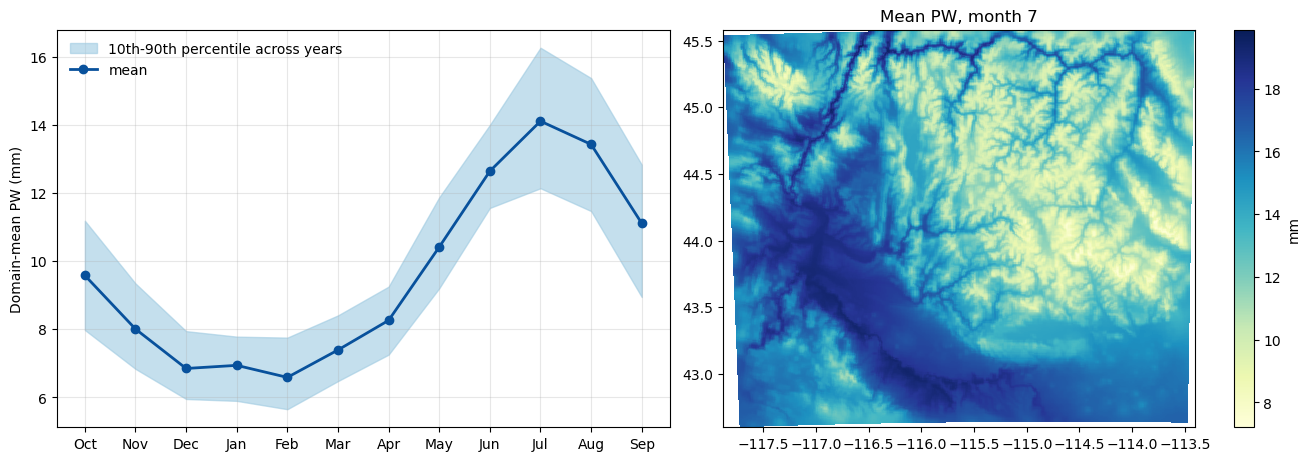

In [7]:
series = monthly.mean(("y", "x")).to_series()
order = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
by_month = series.groupby(series.index.month)
clim = by_month.mean().reindex(order)
lo, hi = by_month.quantile(0.1).reindex(order), by_month.quantile(0.9).reindex(order)
maps = monthly.groupby("time.month").mean()

fig, (ax, axm) = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained", width_ratios=[1.3, 1])
x = np.arange(12)
ax.fill_between(x, lo, hi, color="#9ecae1", alpha=0.6, label="10th-90th percentile across years")
ax.plot(x, clim, "o-", color="#08519c", lw=2, label="mean")
ax.set_xticks(x, ["Oct","Nov","Dec","Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep"])
ax.set_ylabel("Domain-mean PW (mm)"); ax.grid(alpha=0.3); ax.legend(frameon=False)
mo = 7 if 7 in maps.month.values else int(maps.month.values[0])
m = axm.pcolormesh(a3.lon, a3.lat, maps.sel(month=mo), cmap="YlGnBu", shading="auto")
axm.set_title(f"Mean PW, month {mo}"); fig.colorbar(m, ax=axm, label="mm")
plt.show()

## 7. Access patterns: what is fast and what is not
Zarr reads whole chunks. Match the question to the chunk layout:

| You want | Read from | Why |
|---|---|---|
| Whole 3D maps at some hours (training samples, composites, climatologies) | `atmos_3d` | one chunk per hour, exactly what is read |
| Surface maps over days or seasons | `surface_met`, `land_hydro` | one chunk per day |
| Long time series at points | `surface_timeseries` | chunked 1 year × 32 × 32 points |
| A long time series of a 3D variable at one column | rechunk first | from `atmos_3d` every hour reads the full 22 MB map (a month at one column took 72 s) |

Other tips:
- Select (`sel`/`isel`) **before** computing; Dask then reads only those chunks.
- Choose a stride or time window that lines up with chunks (here, any set of whole hours).
- `.persist()` a subset you will reuse, if it fits in the workers' memory.
- Write results to a small NetCDF/Zarr (as above) instead of recomputing.

In [8]:
y, x = a3.sizes["y"] // 2, a3.sizes["x"] // 2
t0 = time.perf_counter(); sm["PSFC"].isel(y=y, x=x).isel(time=slice(0, 744)).values
print(f"31 days of PSFC at one point from surface_met: {time.perf_counter()-t0:.2f} s")
t0 = time.perf_counter(); a3["QVAPOR"].isel(y=y, x=x, time=slice(0, min(48, a3.sizes['time']))).values
print(f"2 days of QVAPOR at one column from atmos_3d: {time.perf_counter()-t0:.2f} s (reads 48 full maps)")

31 days of PSFC at one point from surface_met: 1.36 s


2 days of QVAPOR at one column from atmos_3d: 17.55 s (reads 48 full maps)


## Running this notebook on Borah
Start Jupyter inside a Slurm job so the workers get a compute node's cores:

```bash
# on the login node
srun --partition=bsudfq --cpus-per-task=16 --mem=64G --time=04:00:00 --pty bash
source ~/miniforge3/etc/profile.d/conda.sh && conda activate wrf-zarr
cd ~/idaho-wrf-zarr/examples
jupyter lab --no-browser --ip=$(hostname) --port=8888
```
Then, on your laptop, tunnel to that node (use the node name and the host you `ssh` to):
```bash
ssh -N -L 8888:<node>:8888 -L 8787:<node>:8787 <your-borah-login>
```
and open the `http://127.0.0.1:8888/...` link Jupyter printed. The Dask dashboard is at http://127.0.0.1:8787.

`jupyterlab` is not in the base environment; add it once inside `dev-session`:
`conda install -n wrf-zarr -c conda-forge jupyterlab`.

In [9]:
client.close(); cluster.close()